In [19]:
# pip install torch

In [20]:
import torch
torch.__version__

'2.8.0'

In [21]:
import matplotlib.pyplot as plt
import torchvision
import timm

from torch import nn
from torchvision import transforms

In [22]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [23]:
# Define the transformations
data_transforms = transforms.Compose([
    # 1. Resize the image to 224x224 (This squishes the 640x480 into a square)
    transforms.Resize((224, 224)),
    
    # 2. Convert the image (0-255) to a Tensor (0.0-1.0)
    transforms.ToTensor(),
    
    # 3. Normalize using ImageNet standards
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

In [24]:
train_dir = '/Users/pohsonia/Downloads/state_farm/state_farm_split/train'
val_dir = '/Users/pohsonia/Downloads/state_farm/state_farm_split/val'
test_dir = '/Users/pohsonia/Downloads/state_farm/state_farm_split/test'

In [25]:
from torchvision import datasets
from torch.utils.data import DataLoader

# Load datasets with transforms (resizes to 224x224 automatically)
train_dataset = datasets.ImageFolder(root=train_dir, transform=data_transforms)
val_dataset = datasets.ImageFolder(root=val_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(root=test_dir, transform=data_transforms)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples:   {len(val_dataset)}")
print(f"Test samples:  {len(test_dataset)}")
print(f"Classes: {train_dataset.classes}")

Train samples: 15692
Val samples:   3358
Test samples:  3374
Classes: ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


In [26]:
# Load a pre-trained Vision Transformer (Base model with 16x16 patches)
# 'num_classes=10' automatically replaces the head for you
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=10)

# Verify the output shape
dummy_input = torch.randn(1, 3, 224, 224) 
output = model(dummy_input)
print(output.shape)  # Should be [1, 10]

torch.Size([1, 10])


In [27]:
# Move model to device
model = model.to(device)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print(f"Model on: {device}")
print(f"Optimizer: Adam (lr=1e-4)")
print(f"Loss: CrossEntropyLoss")

Model on: cpu
Optimizer: Adam (lr=1e-4)
Loss: CrossEntropyLoss


In [28]:
from tqdm.notebook import tqdm

# Training loop
NUM_EPOCHS = 5

for epoch in range(NUM_EPOCHS):
    # ---------- Training phase ----------
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")
    for images, labels in train_bar:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Track metrics
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        # Update progress bar with live metrics
        train_bar.set_postfix(loss=running_loss / (train_bar.n + 1),
                              acc=f"{100.0 * correct / total:.2f}%")

    train_loss = running_loss / len(train_loader)
    train_acc = 100.0 * correct / total

    # ---------- Validation phase ----------
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]  ")
    with torch.no_grad():
        for images, labels in val_bar:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

            val_bar.set_postfix(loss=val_loss / (val_bar.n + 1),
                                acc=f"{100.0 * val_correct / val_total:.2f}%")

    val_loss /= len(val_loader)
    val_acc = 100.0 * val_correct / val_total

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    print("-" * 70)

Epoch 1/5 [Train]:   0%|          | 0/491 [00:00<?, ?it/s]

Epoch 1/5 [Val]  :   0%|          | 0/105 [00:00<?, ?it/s]

Epoch [1/5] Train Loss: 0.8115 | Train Acc: 70.41% | Val Loss: 0.1246 | Val Acc: 96.31%
----------------------------------------------------------------------


Epoch 2/5 [Train]:   0%|          | 0/491 [00:00<?, ?it/s]

Epoch 2/5 [Val]  :   0%|          | 0/105 [00:00<?, ?it/s]

Epoch [2/5] Train Loss: 0.0847 | Train Acc: 97.55% | Val Loss: 0.1220 | Val Acc: 96.52%
----------------------------------------------------------------------


... (5 outputs left out)

Epoch [4/5] Train Loss: 0.0473 | Train Acc: 98.57% | Val Loss: 0.0665 | Val Acc: 97.97%
----------------------------------------------------------------------


Epoch 5/5 [Train]:   0%|          | 0/491 [00:00<?, ?it/s]

Epoch 5/5 [Val]  :   0%|          | 0/105 [00:00<?, ?it/s]

Epoch [5/5] Train Loss: 0.0276 | Train Acc: 99.23% | Val Loss: 0.0814 | Val Acc: 97.50%
----------------------------------------------------------------------


In [ ]:
# ---------- Final Test Evaluation ----------
model.eval()
test_loss = 0.0
test_correct = 0
test_total = 0

test_bar = tqdm(test_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]  ")
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

        test_bar.set_postfix(loss=test_loss / (test_bar.n + 1),
                              acc=f"{100.0 * test_correct / test_total:.2f}%")

test_loss /= len(test_loader)
test_acc = 100.0 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

Test Loss: 0.0890 | Test Acc: 97.33%


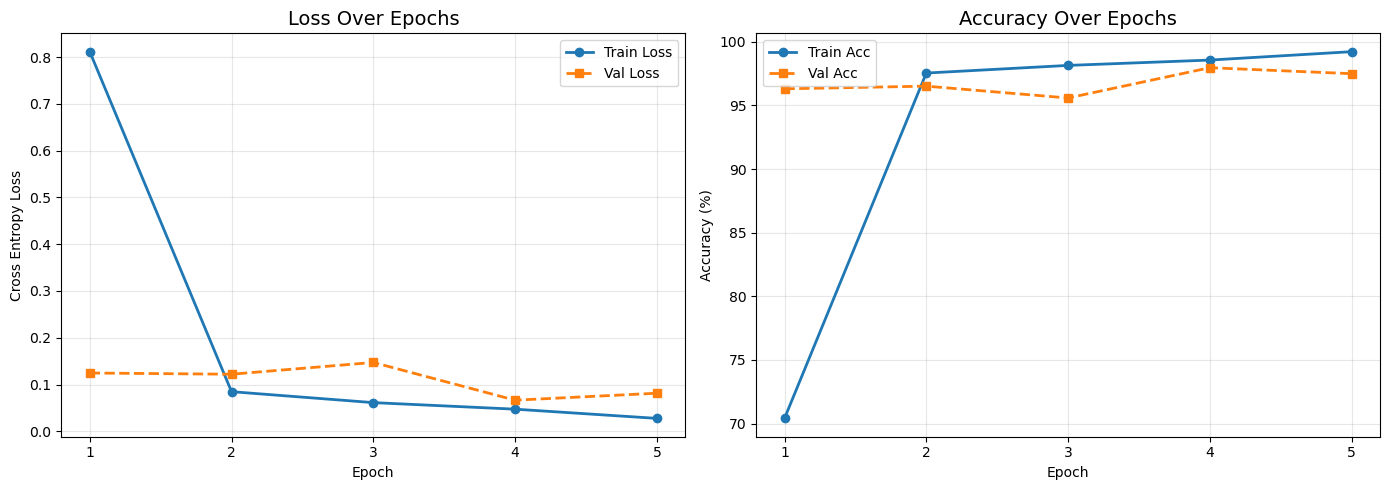

In [ ]:
import matplotlib.pyplot as plt

epochs = [1, 2, 3, 4, 5]
train_losses = [0.8115, 0.0847, 0.0613, 0.0473, 0.0276]
val_losses = [0.1246, 0.1220, 0.1472, 0.0665, 0.0814]
train_accs = [70.41, 97.55, 98.15, 98.57, 99.23]
val_accs = [96.31, 96.52, 95.59, 97.97, 97.50]

plt.figure(figsize=(14, 5))

# --- Plot 1: Loss ---
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss', marker='o', linewidth=2)
plt.plot(epochs, val_losses, label='Val Loss', marker='s', linestyle='--', linewidth=2)
plt.title('Loss Over Epochs', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Cross Entropy Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)

# --- Plot 2: Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accs, label='Train Acc', marker='o', linewidth=2)
plt.plot(epochs, val_accs, label='Val Acc', marker='s', linestyle='--', linewidth=2)
plt.title('Accuracy Over Epochs', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(epochs)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

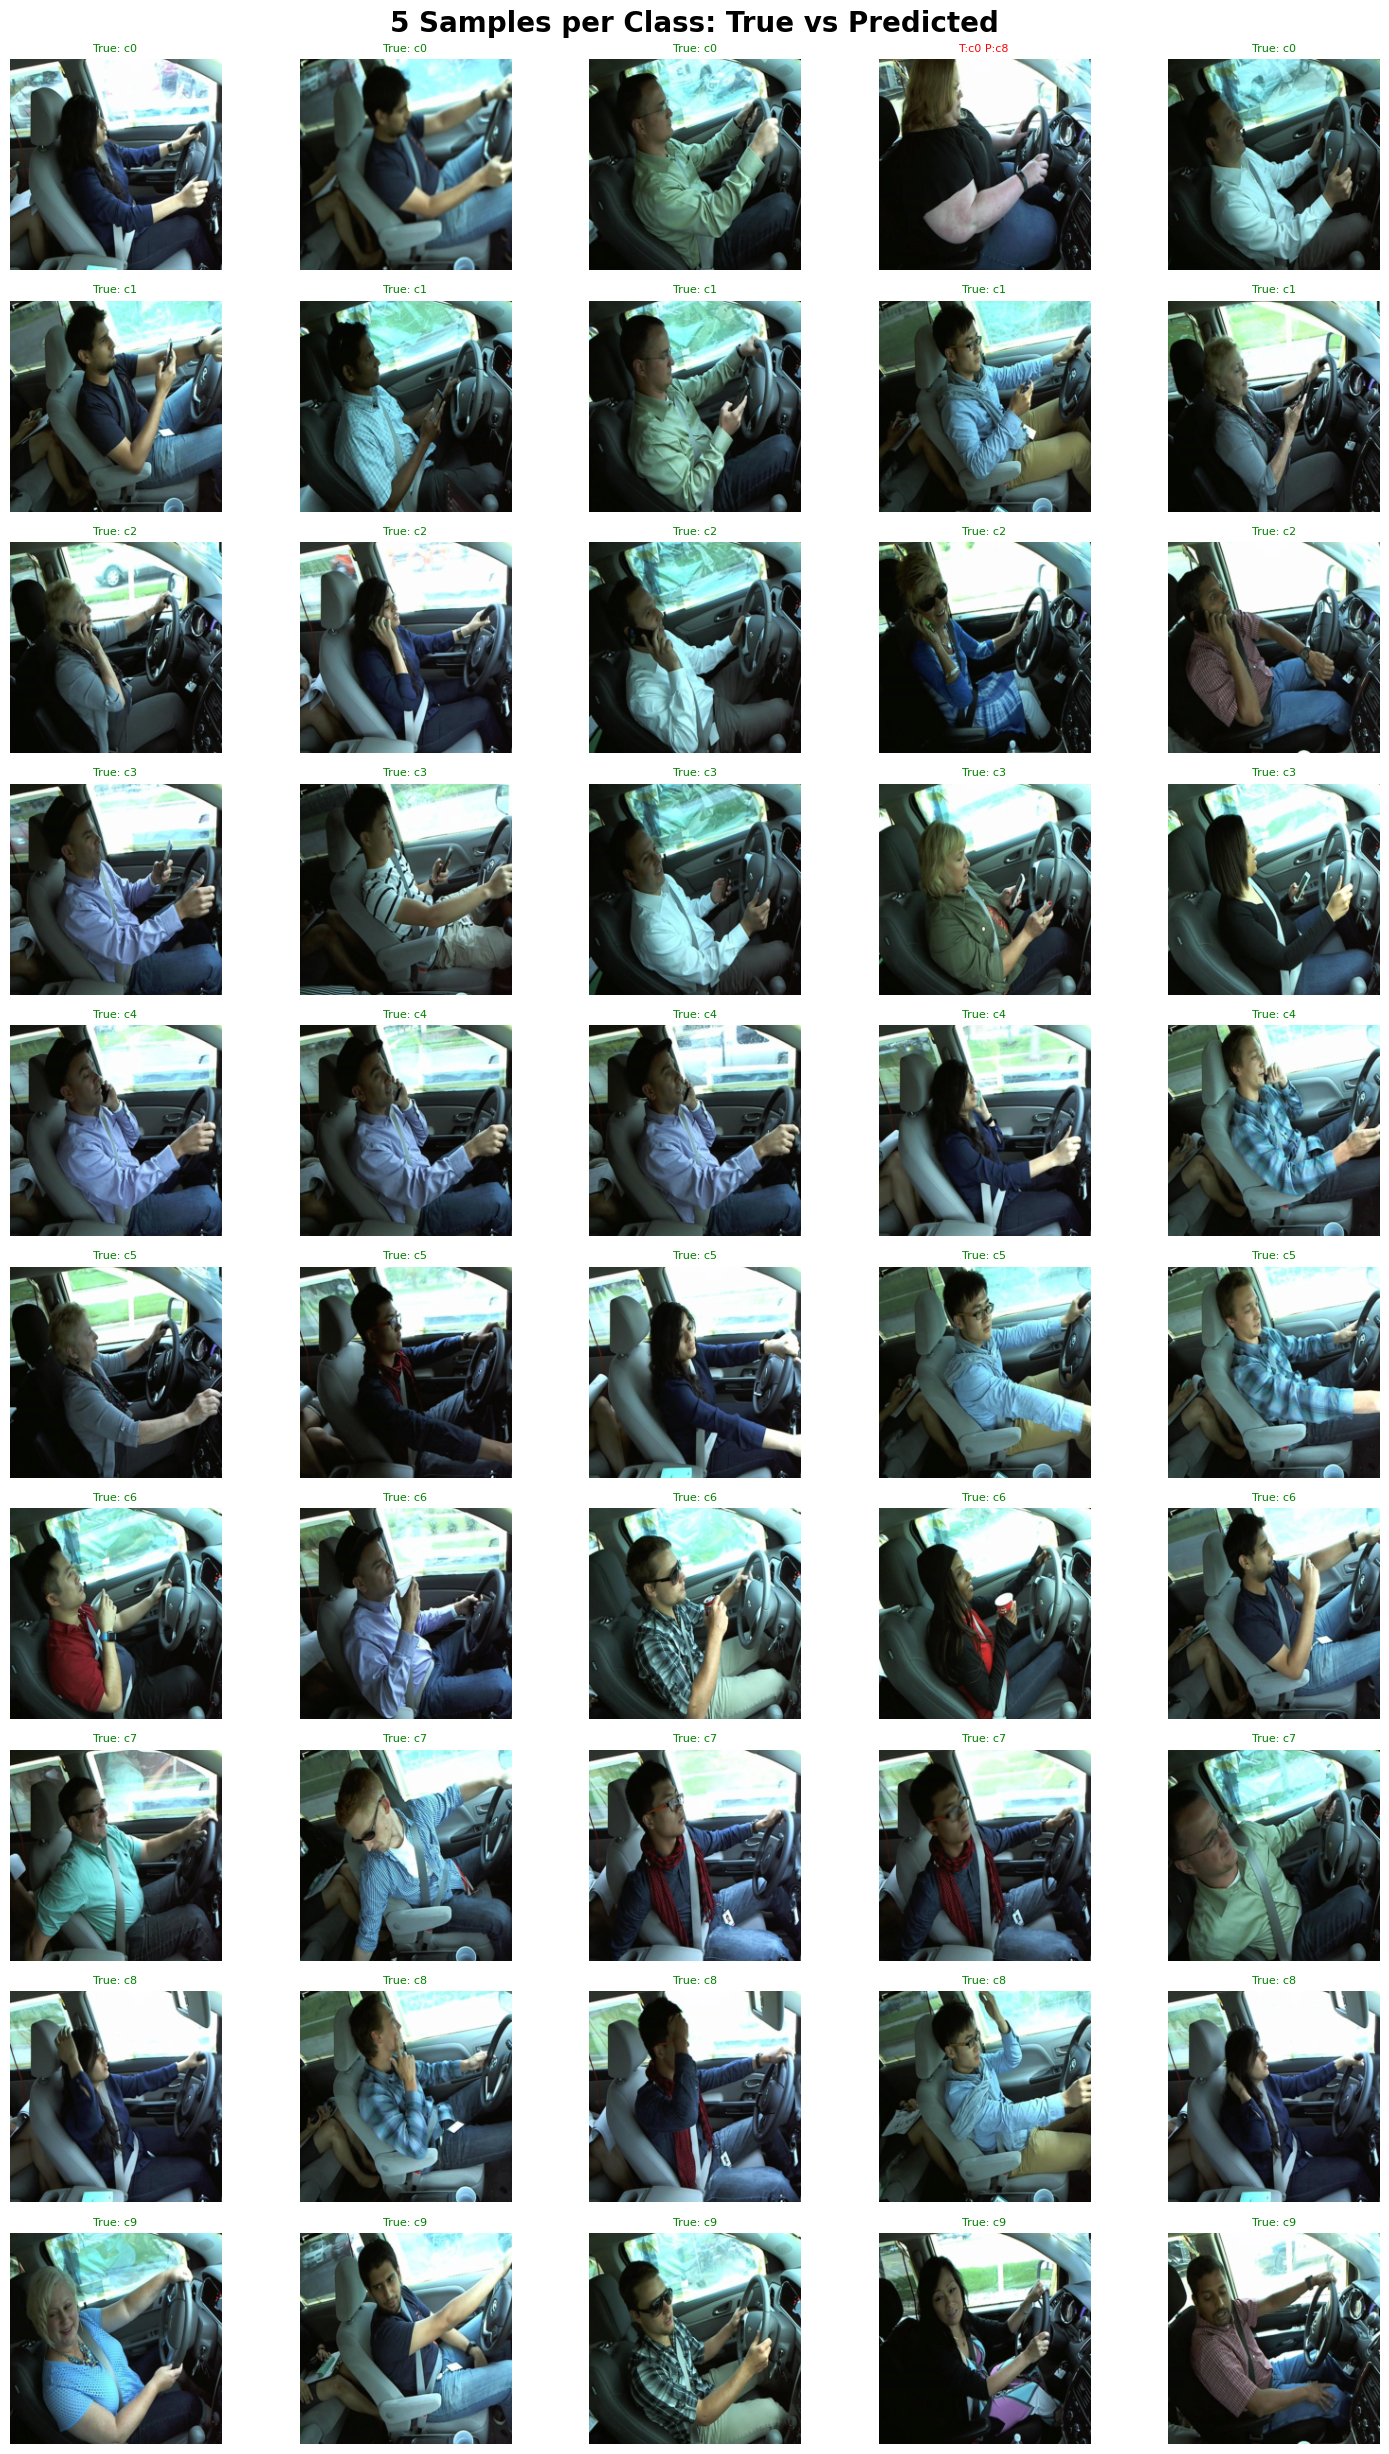

In [36]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# 1. Collect 5 images for each class (c0-c9)
samples_per_class = 5
class_samples = {i: [] for i in range(10)}
total_needed = 10 * samples_per_class

# Iterate through the test_loader
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        for i in range(len(labels)):
            label = labels[i].item()
            if len(class_samples[label]) < samples_per_class:
                # Store the image and the model's prediction for it
                img = images[i].unsqueeze(0).to(device)
                output = model(img)
                _, pred = torch.max(output, 1)
                
                class_samples[label].append({
                    'image': images[i],
                    'prediction': pred.item()
                })
        
        # Stop if we have collected 5 images for every class
        if all(len(v) == samples_per_class for v in class_samples.values()):
            break

# 2. Helper function to un-normalize
def imshow_ax(tensor, ax, title=None, color='black'):
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    if title:
        ax.set_title(title, color=color, fontsize=8)
    ax.axis('off')

# 3. Plotting the grid (10 rows x 5 columns)
fig, axes = plt.subplots(10, 5, figsize=(15, 25))
class_names = test_dataset.classes # ['c0', 'c1', ..., 'c9']

for class_idx in range(10):
    samples = class_samples[class_idx]
    for sample_idx in range(samples_per_class):
        ax = axes[class_idx, sample_idx]
        
        data = samples[sample_idx]
        image = data['image']
        pred_idx = data['prediction']
        
        true_label = class_names[class_idx]
        pred_label = class_names[pred_idx]
        
        # Determine color and text
        if class_idx == pred_idx:
            color = 'green'
            title_text = f"True: {true_label}"
        else:
            color = 'red'
            title_text = f"T:{true_label} P:{pred_label}"
            
        imshow_ax(image, ax, title=title_text, color=color)

plt.tight_layout()
plt.subplots_adjust(top=0.96)
fig.suptitle("5 Samples per Class: True vs Predicted", fontsize=20, fontweight='bold')
plt.show()